![Banner](../../../../Images/Banner/03_spatial_analysis/03_04_banner_spatial_analysis_Multi_Criteria.png)



# Advanced Fuzzy Suitability: Sensitivity, Weighting, and Rule-based Inference



Gamma / parameter sensitivity (Jaccard), weighted fuzzy operators, and a
vectorized Mamdani FIS: all on Module 7 layers in `Data/03_spatial_analysis/MCSM_data/`.

1. [Comparing maps: the Jaccard index of top areas](#comparing-maps-the-jaccard-index-of-top-areas)
2. [Sensitivity to γ](#sensitivity-to-γ)
3. [Sensitivity to membership parameters](#sensitivity-to-membership-parameters)
4. [Weighting fuzzy criteria](#weighting-fuzzy-criteria)
5. [Rule-based suitability: a Mamdani fuzzy inference system](#rule-based-suitability-a-mamdani-fuzzy-inference-system)
   - [5.1 Defining linguistic terms](#defining-linguistic-terms)
   - [5.2 The rule base](#the-rule-base)
   - [5.3 Vectorized evaluation over the raster](#vectorized-evaluation-over-the-raster)
   - [5.4 Validating against `scikit-fuzzy`'s control API](#validating-against-scikit-fuzzys-control-api)
   - [5.5 FIS vs. fuzzy overlay](#fis-vs-fuzzy-overlay)
6. [Choosing a method](#choosing-a-method)
7. [Exercises](#exercises)
8. [Key takeaways](#key-takeaways)
9. [Part II summary](#part-ii-summary)




**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README. It also uses `scikit-fuzzy`, which no GeoLattice option installs: `pip install scikit-fuzzy`.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Standard library imports for path setup.
import warnings  # silence benign RuntimeWarnings
from pathlib import Path  # filesystem paths for MCSM sample data

# Third-party numeric / plotting stack used throughout this notebook.
import matplotlib.pyplot as plt  # figure and axes creation for sensitivity maps
import numpy as np  # array ops for memberships and FIS evaluation
import pandas as pd  # tabular sensitivity / comparison summaries

# ===================================================================
# Locate the repository root, import fuzzy helpers, reload solar_layers.npz.
# ===================================================================
# The installed package lives in src/; the repository root is its parent.
import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    raise FileNotFoundError("Could not find the GeoLattice repository root.")

DATA_DIR = ROOT / "Data" / "03_spatial_analysis" / "MCSM_data"  # shared MCSM sample-data folder
DATA_DIR.mkdir(parents=True, exist_ok=True)  # create it if missing

warnings.filterwarnings("ignore", category=RuntimeWarning)  # quiet numeric warnings
pd.set_option("display.width", 120)  # wider DataFrame previews
plt.rcParams["figure.figsize"] = [9, 6]  # default figure size for maps

# Import the fuzzy MCSM module and named helpers used below.
import geolattice.spatial_analysis.multi_criteria_suitability_analysis as fz  # fuzzy API alias
from geolattice.spatial_analysis.multi_criteria_suitability_analysis import (
    SuitabilityAnalysisError,  # typed error for invalid inputs
    categorical_and,  # Boolean AND helper
    categorical_or,  # Boolean OR helper
    criteria_count,  # k-of-n helper
    hybrid_suitability,  # constrained continuous scores
    jaccard_index,  # top-set overlap between two maps
    limiting_criterion,  # weakest-membership helper
    mamdani,  # vectorised Mamdani FIS defuzzification
    minmax_normalize,  # min-max standardisation
    monte_carlo_weights,  # weight uncertainty helper
    overlay,  # fuzzy overlay operators
    percentile_rank_normalize,  # rank-based standardisation
    perturb_weights,  # OAT weight perturbation
    spread_for_small,  # calibrate Small-function spread
    top_quantile_mask,  # Boolean mask of top-q cells
    trapezoidal_mf,  # trapezoid membership
    triangular_mf,  # triangle membership
    weighted_fuzzy_overlay,  # weighted fuzzy gamma-style overlay
    weighted_linear_combination,  # WLC helper
)

from scipy.stats import spearmanr  # rank correlation for map agreement
import skfuzzy as skf  # linguistic membership shapes for the FIS

# Reload terrain memberships and masks saved by the fuzzy raster notebook.
L = np.load(str(DATA_DIR / "solar_layers.npz"))  # compressed intermediate layers

slope_pct, dev_south, tpi, dist_stream = L["slope_pct"], L["dev_south"], L["tpi"], L["dist_stream"]  # criteria
feasible, hs, EXTENT = L["feasible"], L["hs"], L["extent"]  # mask, hillshade, map extent
NAMES = ["Slope", "Exposure", "Topographic position", "Stream distance"]  # criterion display names
MUS = [L["mu_slope"], L["mu_exposure"], L["mu_tpi"], L["mu_stream"]]  # baseline memberships


def show(arr, title, ax, cmap="RdYlGn", vmin=0, vmax=1):
    """Drape a suitability array over hillshade on feasible land only."""
    ax.imshow(hs, cmap="gray", extent=EXTENT)  # hillshade basemap
    im = ax.imshow(np.where(feasible, arr, np.nan), cmap=cmap, vmin=vmin, vmax=vmax,
                   extent=EXTENT, alpha=0.85)  # suitability overlay
    ax.set_title(title, fontsize=10)  # panel title
    ax.set_axis_off()  # hide ticks
    return im  # return mappable for a shared colourbar


baseline = np.where(feasible, fz.overlay(MUS, "gamma", gamma=0.8), np.nan)  # Module 7 reference map
print("Feasible cells:", int(feasible.sum()))  # confirm mask size



Feasible cells: 104961


## Comparing maps: the Jaccard index of top areas

Suitability values from different model variants are not on comparable scales. Product values, for example, are always lower than Sum values. A fairer comparison asks whether two variants identify **the same best land**.

1. Take the **top 20%** of feasible cells from each map.
2. Compute the **Jaccard index**, |A ∩ B| / |A ∪ B|. It is 1 when the two sets are identical and 0 when they are disjoint.

**Spearman's ρ** over all feasible cells complements Jaccard by measuring agreement in the overall ordering.

In [2]:
# Helpers to compare an alternate map against the baseline (Jaccard + Spearman).
rng = np.random.default_rng(0)  # reproducible sampler
SAMPLE = rng.choice(np.flatnonzero(feasible), 20_000, replace=False)  # subsample for fast Spearman


def compare(arr, ref=baseline):
    """Return (Jaccard of top-20% masks, Spearman rho on a feasible subsample)."""
    rho = spearmanr(np.ravel(arr)[SAMPLE], np.ravel(ref)[SAMPLE], nan_policy="omit")[0]  # rank agreement
    return jaccard_index(top_quantile_mask(arr, mask=feasible), top_quantile_mask(ref, mask=feasible)), rho  # overlap + rho


BASE_TOP = top_quantile_mask(baseline, mask=feasible, q=0.80)  # top 20% of baseline scores
print("Baseline top-20% area (km²):", round(BASE_TOP.sum() * 0.81 / 100, 1))  # 90 m cells -> 0.81 ha each



Baseline top-20% area (km²): 170.0


## Sensitivity to γ

In [3]:
# Sweep gamma and measure agreement of each map with the gamma=0.8 baseline.
rows = []  # one row per gamma value
for g in [0.0, 0.2, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 1.0]:
    arr = fz.overlay(MUS, "gamma", gamma=g)  # suitability at this gamma
    j, rho = compare(arr)  # agreement with baseline
    rows.append({"gamma": g, "Jaccard vs gamma=0.8": j, "Spearman rho": rho,
                 "area >= 0.85 (km2)": (np.nan_to_num(np.where(feasible, arr, np.nan)) >= 0.85).sum() * 0.0081})  # high-mu area
gsens = pd.DataFrame(rows).round(3)  # gamma sensitivity table
gsens  # display



,gamma,Jaccard vs gamma=0.8,Spearman rho,area >= 0.85 (km2)
0,0.00,0.999,1.000,19.383
1,0.20,0.999,1.000,25.021
2,0.40,1.000,1.000,35.373
3,0.50,1.000,1.000,44.574
4,0.60,1.000,1.000,60.863
5,0.70,1.000,1.000,91.514
6,0.80,1.000,1.000,162.494
7,0.90,1.000,1.000,350.317
8,0.95,0.998,0.999,592.474
9,1.00,0.236,0.591,837.451


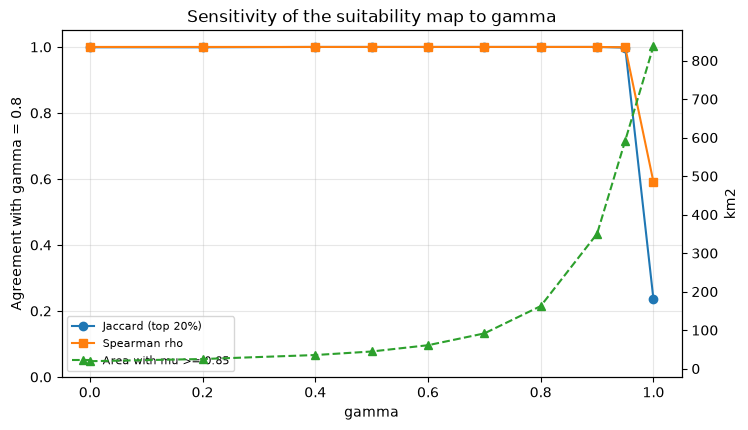

In [4]:
# Plot Jaccard / Spearman agreement and high-suitability area against gamma.
fig, ax1 = plt.subplots(figsize=(8, 4.5))  # dual-axis sensitivity figure
ax1.plot(gsens["gamma"], gsens["Jaccard vs gamma=0.8"], marker="o", label="Jaccard (top 20%)")  # set overlap
ax1.plot(gsens["gamma"], gsens["Spearman rho"], marker="s", label="Spearman rho")  # rank agreement
ax1.set(xlabel="gamma", ylabel="Agreement with gamma = 0.8", ylim=(0, 1.05))  # left axis
ax2 = ax1.twinx()  # right axis for area
ax2.plot(gsens["gamma"], gsens["area >= 0.85 (km2)"], color="tab:green", ls="--", marker="^",
         label="Area with mu >= 0.85")  # high-mu area curve
ax2.set_ylabel("km2")  # area axis label
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()  # combine legends
ax1.legend(h1 + h2, l1 + l2, loc="lower left", fontsize=8)  # unified legend
ax1.set_title("Sensitivity of the suitability map to gamma")  # panel title
ax1.grid(alpha=0.3)  # light grid
plt.show()  # render the figure



Two lessons:

- The **ranking is unchanged** for every γ below about 0.95 (Jaccard and ρ ≈ 1). With four criteria, the fuzzy Sum is close to 1 almost everywhere, so Gamma ≈ Product^(1-γ). That is a monotonic transformation of Product, so the *order* of cells cannot change. Only at γ = 1, the saturated Sum, does the ranking collapse.
- The **amount of land above a fixed threshold** changes greatly with γ, from about 20 km² at γ = 0 to about 350 km² at γ = 0.9. Any absolute threshold, like the 0.85 used in Module 7, must therefore be reported **together with the γ used**, or replaced by a relative rule such as "top 20%".

In practice, then, **γ calibrates the values, while the membership functions determine the ranking**. The next section tests those functions.

## Sensitivity to membership parameters

Membership midpoints and spreads come from expert judgment, so each one is tested **one at a time (OAT)** by varying it ±25% while holding the others at baseline. The result is recomputed with Gamma 0.8 and compared with the baseline using Jaccard.

In [5]:
# Rebuild memberships from parameters so OAT +/-25% perturbations are easy.
def memberships(slope_mid=4, slope_sp=4, south_mu90=0.3, tpi_lo=-6, tpi_hi=4, stream_mid=300, stream_sp=3):
    """Return the four membership rasters under the given parameterisation."""
    asp_sp = -np.log(south_mu90) / 90 ** 2  # Gaussian spread from mu(90 deg)
    mu_exp = np.maximum(fz.gaussian(dev_south, 0, asp_sp), fz.small(slope_pct, 1, 6))  # exposure OR flat
    return [fz.small(slope_pct, slope_mid, slope_sp), mu_exp,
            fz.linear(tpi, tpi_lo, tpi_hi), fz.large(dist_stream, stream_mid, stream_sp)]  # four criteria


BASE = dict(slope_mid=4, slope_sp=4, south_mu90=0.3, tpi_lo=-6, tpi_hi=4, stream_mid=300, stream_sp=3)  # baseline params
# Confirm the parametric memberships match the saved Module 7 arrays.
assert np.allclose(np.nan_to_num(fz.overlay(memberships(), "gamma", gamma=0.8)),
                   np.nan_to_num(fz.overlay(MUS, "gamma", gamma=0.8)))  # sanity check

rows = []  # one row per parameter x direction
for p, v in BASE.items():
    for f in (0.75, 1.25):
        new = v * f  # +/-25% perturbation
        if p == "south_mu90":
            new = min(new, 0.95)  # keep membership parameter in (0, 1)
        arr = fz.overlay(memberships(**{**BASE, p: new}), "gamma", gamma=0.8)  # perturbed map
        j, rho = compare(arr)  # agreement with baseline
        rows.append({"parameter": p, "change": f"{'-' if f < 1 else '+'}25%", "value": round(new, 3),
                     "Jaccard": j, "Spearman rho": rho})  # record row
psens = pd.DataFrame(rows)  # parameter sensitivity table
psens.round(3)  # display



,parameter,change,value,Jaccard,Spearman rho
0,slope_mid,-25%,3.000,0.842,0.990
1,slope_mid,+25%,5.000,0.908,0.996
2,slope_sp,-25%,3.000,0.960,0.999
3,slope_sp,+25%,5.000,0.973,0.999
4,south_mu90,-25%,0.225,0.934,0.997
5,south_mu90,+25%,0.375,0.936,0.997
6,tpi_lo,-25%,-4.500,0.909,0.981
7,tpi_lo,+25%,-7.500,0.921,0.991
8,tpi_hi,-25%,3.000,0.956,1.000
9,tpi_hi,+25%,5.000,0.971,1.000


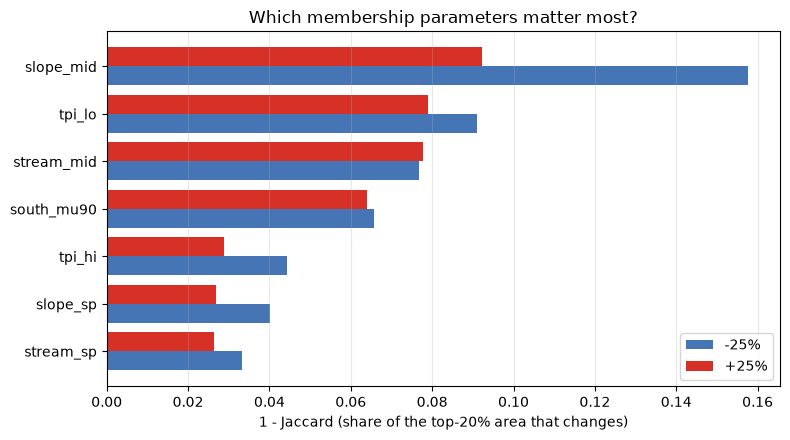

In [6]:
# Tornado-style bars: how much of the top-20% area changes under +/-25% parameter shifts.
tor = psens.pivot(index="parameter", columns="change", values="Jaccard")  # Jaccard by direction
tor["min"] = tor.min(axis=1)  # worst-case Jaccard across directions
tor = tor.sort_values("min", ascending=False)  # most stable parameters at the top

fig, ax = plt.subplots(figsize=(8, 4.5))  # tornado chart
y = np.arange(len(tor))  # parameter positions
ax.barh(y - 0.2, 1 - tor["-25%"], height=0.4, label="-25%", color="#4575b4")  # share that changes
ax.barh(y + 0.2, 1 - tor["+25%"], height=0.4, label="+25%", color="#d73027")  # share that changes
ax.set_yticks(y, tor.index)  # parameter names
ax.set(xlabel="1 - Jaccard (share of the top-20% area that changes)",
       title="Which membership parameters matter most?")  # labels
ax.legend(); ax.grid(alpha=0.3, axis="x")  # legend and light grid
plt.tight_layout()  # tighten spacing
plt.show()  # render the figure



The **slope midpoint** is the most influential parameter: a ±25% change alters 9-16% of the top area. The lower TPI bound is next. Parameters with the longest bars deserve the most care. They should be justified with literature, local data, or stakeholder elicitation, and reported with their uncertainty. Parameters with short bars can be set by reasonable judgment.

Part III extends this OAT analysis to **global** methods (Monte Carlo and Sobol indices), which also capture interactions between parameters.

## Weighting fuzzy criteria

Standard fuzzy overlay treats every criterion as equally important. Three common ways to add **importance weights** $w_i$ (with $\sum w_i = 1$) are listed below. Each reduces to its unweighted version when all weights are equal, with the inputs raised to $n w_i$:

| Weighted operator | Formula |
|---|---|
| Weighted product (geometric mean) | $\prod \mu_i^{\,w_i}$ |
| Weighted sum | $1 - \prod (1 - \mu_i)^{w_i}$ |
| Weighted gamma | $(\text{W-Sum})^{\gamma} \cdot (\text{W-Product})^{1-\gamma}$ |

Raising a membership to a power above 1 acts like the *very* hedge, making that criterion more demanding. A criterion with a larger weight therefore has more influence on the result. This approach follows the importance-weighting method of Yager (1978).

In [7]:
# Confirm equal-weight weighted_fuzzy_overlay matches unweighted Gamma 0.8.
eq = weighted_fuzzy_overlay(MUS, [1, 1, 1, 1])  # equal weights
print("Equal weights reproduce Gamma 0.8:",
      np.allclose(np.nan_to_num(eq), np.nan_to_num(fz.overlay(MUS, "gamma", gamma=0.8))))  # should be True



Equal weights reproduce Gamma 0.8: True


Two stakeholder views are compared:

- An **engineering** view, where grading cost (slope) and flood risk (streams) dominate: weights 0.35, 0.15, 0.15, 0.35.
- An **energy-yield** view, where sun exposure dominates: weights 0.2, 0.5, 0.1, 0.2.

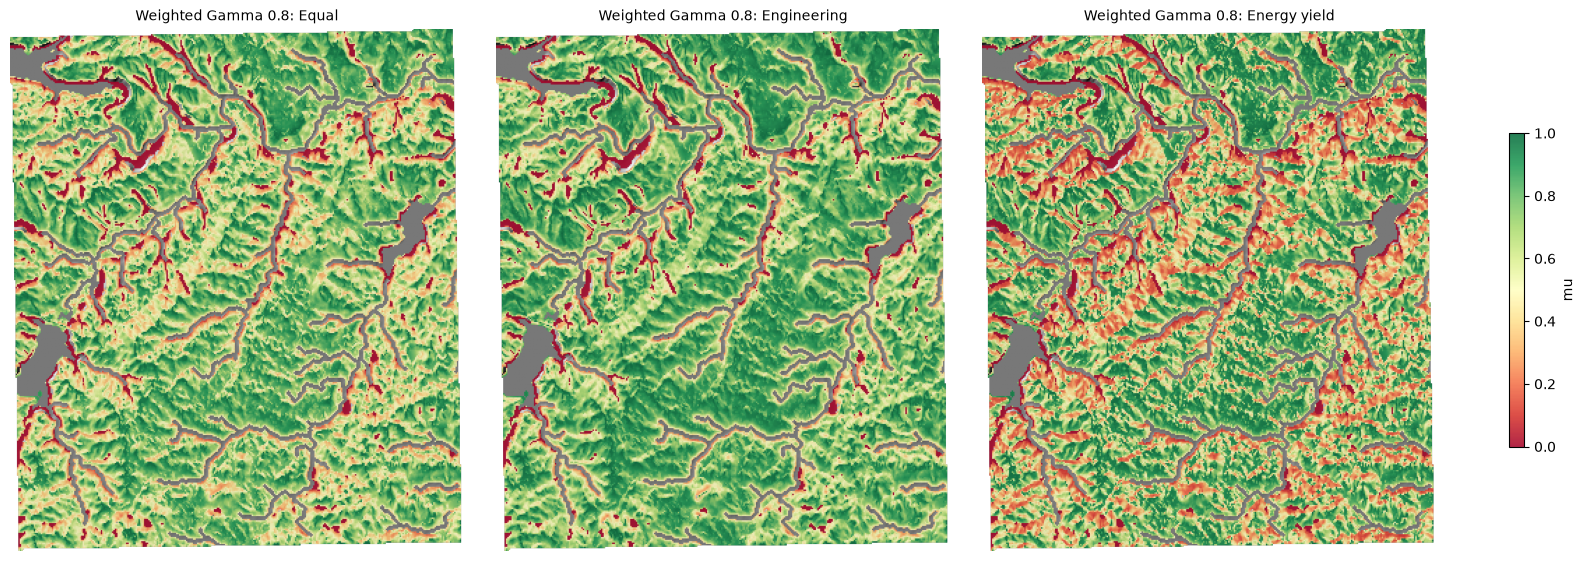

,Jaccard vs equal,Spearman rho vs equal
Equal,1.000,1.000
Engineering,0.817,0.973
Energy yield,0.650,0.943


In [8]:
# Compare equal, engineering, and energy-yield weight vectors under weighted fuzzy overlay.
W = {"Equal": [0.25, 0.25, 0.25, 0.25],  # uniform importance
     "Engineering": [0.35, 0.15, 0.15, 0.35],  # emphasise slope + stream distance
     "Energy yield": [0.20, 0.50, 0.10, 0.20]}  # emphasise exposure / aspect

wres = {k: weighted_fuzzy_overlay(MUS, w) for k, w in W.items()}  # one map per weight vector

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), layout="constrained")  # three stakeholder maps
for ax, (k, arr) in zip(axes, wres.items()):
    im = show(arr, f"Weighted Gamma 0.8: {k}", ax)  # suitability under this weighting
fig.colorbar(im, ax=axes, shrink=0.6, label="mu")  # shared colourbar
plt.show()  # render the figure

pd.DataFrame({k: dict(zip(["Jaccard vs equal", "Spearman rho vs equal"], compare(v, wres["Equal"])))
              for k, v in wres.items()}).T.round(3)  # agreement vs equal weights



The two stakeholder views identify noticeably different top areas: about 18% of the top area changes under the engineering weights and 35% under the energy-yield weights. Raising the weight on exposure moves the best land toward south-facing ground, while the engineering weights favor gentle land far from streams. Making these weightings **explicit and visible** helps a group reach agreement, because the disagreement becomes something on the map that everyone can look at.

## Rule-based suitability: a Mamdani fuzzy inference system

Fuzzy overlay combines criteria with **one** operator everywhere. A **fuzzy inference system (FIS)** instead uses **expert rules** expressed in words:

> IF slope is *gentle* AND aspect is *south* AND streams are *far*, THEN suitability is *high*.

A Mamdani FIS has four steps:

1. **Fuzzify** the inputs with linguistic terms, such as slope = {flat, gentle, moderate, steep}.
2. **Evaluate the rules**. Each rule's *firing strength* is the minimum (AND) or maximum (OR) of its antecedent memberships.
3. **Implication and aggregation**. Each rule's output set is clipped at its firing strength, and the clipped sets are combined with max.
4. **Defuzzify**. The **centroid** of the aggregated output set gives a crisp score from 0 to 100.

The advantage is **interpretability and flexibility**. Rules can express interactions that a single operator cannot, for example *aspect only matters on sloping land*.

### Defining linguistic terms

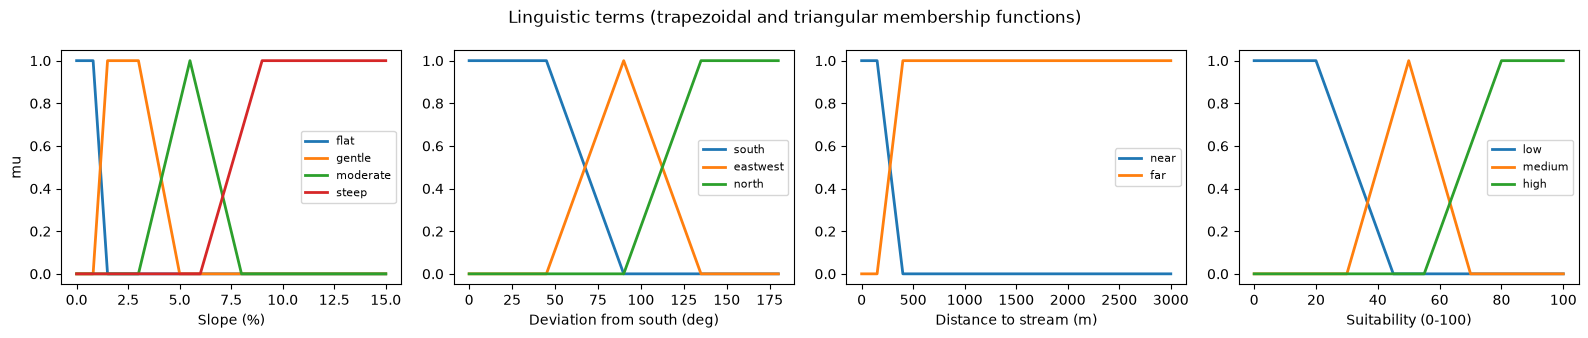

In [9]:
# Define linguistic universes and trapezoid/triangle membership terms for the FIS.
U = {
    "slope":  np.linspace(0, 15, 301),  # slope (%) universe
    "dev":    np.linspace(0, 180, 181),  # south-deviation (deg) universe
    "stream": np.linspace(0, 3000, 301),  # stream distance (m) universe
    "out":    np.linspace(0, 100, 101),  # suitability output (0-100)
}

TERMS = {
    "slope": {"flat":     skf.trapmf(U["slope"], [0, 0, 0.8, 1.5]),  # nearly level
              "gentle":   skf.trapmf(U["slope"], [0.8, 1.5, 3, 5]),  # easy to grade
              "moderate": skf.trimf(U["slope"], [3, 5.5, 8]),  # transitional
              "steep":    skf.trapmf(U["slope"], [6, 9, 15, 15])},  # costly / unsuitable
    "dev":   {"south":    skf.trapmf(U["dev"], [0, 0, 45, 90]),  # favourable aspect
              "eastwest": skf.trimf(U["dev"], [45, 90, 135]),  # intermediate aspect
              "north":    skf.trapmf(U["dev"], [90, 135, 180, 180])},  # unfavourable aspect
    "stream": {"near":    skf.trapmf(U["stream"], [0, 0, 150, 400]),  # flood / setback risk
               "far":     skf.trapmf(U["stream"], [150, 400, 3000, 3000])},  # safer setback
    "out":   {"low":      skf.trapmf(U["out"], [0, 0, 20, 45]),  # low suitability
              "medium":   skf.trimf(U["out"], [30, 50, 70]),  # medium suitability
              "high":     skf.trapmf(U["out"], [55, 80, 100, 100])},  # high suitability
}

# Plot the linguistic terms for each variable.
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))  # four variable panels
for ax, (var, label) in zip(axes, [("slope", "Slope (%)"), ("dev", "Deviation from south (deg)"),
                                   ("stream", "Distance to stream (m)"), ("out", "Suitability (0-100)")]):
    for term, mf in TERMS[var].items():
        ax.plot(U[var], mf, lw=2, label=term)  # membership curve for this term
    ax.set(xlabel=label, ylim=(-0.05, 1.05))  # axis limits
    ax.legend(fontsize=8)  # term legend
axes[0].set_ylabel("mu")  # membership axis
plt.suptitle("Linguistic terms (trapezoidal and triangular membership functions)")  # figure title
plt.tight_layout()  # tighten spacing
plt.show()  # render the figure



### The rule base

| # | IF | THEN suitability is |
|---|---|---|
| 1 | slope is **flat** AND streams are **far** | high |
| 2 | slope is **gentle** AND aspect is **south** AND streams are **far** | high |
| 3 | slope is **gentle** AND aspect is **east/west** AND streams are **far** | medium |
| 4 | slope is **gentle** AND aspect is **north** AND streams are **far** | medium |
| 5 | slope is **moderate** AND aspect is **south** AND streams are **far** | medium |
| 6 | slope is **moderate** AND aspect is (**east/west** OR **north**) | low |
| 7 | slope is **steep** | low |
| 8 | streams are **near** | low |

Rule 1 encodes the *flatness override* from Module 7 directly in words. TPI is left out to keep the rule base readable, and adding it is an exercise.

### Vectorized evaluation over the raster

`skfuzzy.interp_membership` accepts whole arrays, so every rule is evaluated for all cells at once. Aggregation creates an array of shape (*cells* × 101 output points), which is about 10 million values and fits easily in memory.

In [10]:
# Evaluate a vectorised Mamdani FIS on all feasible cells using eight IF-THEN rules.
idx = np.flatnonzero(feasible)  # flat indices of feasible cells
x_slope = np.clip(np.ravel(slope_pct)[idx], 0, 15)  # slope inputs clipped to universe
x_dev = np.ravel(dev_south)[idx]  # aspect-deviation inputs
x_stream = np.clip(np.ravel(dist_stream)[idx], 0, 3000)  # stream-distance inputs clipped


def m(var, term, x):
    """Interpolate a linguistic membership for array-valued inputs x."""
    return skf.interp_membership(U[var], TERMS[var][term], x)  # membership of x in term


S = {t: m("slope", t, x_slope) for t in TERMS["slope"]}  # slope-term memberships
A = {t: m("dev", t, x_dev) for t in TERMS["dev"]}  # aspect-term memberships
D = {t: m("stream", t, x_stream) for t in TERMS["stream"]}  # stream-term memberships

RULES = [  # (firing strength, output term)
    (np.minimum(S["flat"], D["far"]), "high"),  # flat + far -> high
    (np.minimum.reduce([S["gentle"], A["south"], D["far"]]), "high"),  # gentle south far -> high
    (np.minimum.reduce([S["gentle"], A["eastwest"], D["far"]]), "medium"),  # gentle E/W far -> medium
    (np.minimum.reduce([S["gentle"], A["north"], D["far"]]), "medium"),  # gentle north far -> medium
    (np.minimum.reduce([S["moderate"], A["south"], D["far"]]), "medium"),  # moderate south far -> medium
    (np.minimum(S["moderate"], np.maximum(A["eastwest"], A["north"])), "low"),  # moderate non-south -> low
    (S["steep"], "low"),  # steep anywhere -> low
    (D["near"], "low"),  # near stream anywhere -> low
]

fis_vals = mamdani(RULES, TERMS["out"], U["out"])  # vectorised centroid defuzzification
fis = np.full(feasible.shape, np.nan)  # map-shaped FIS output
fis.ravel()[idx] = fis_vals  # scatter FIS values onto feasible cells

print(f"FIS output: {np.nanmin(fis_vals):.1f}-{np.nanmax(fis_vals):.1f} | "
      f"cells with no rule firing: {np.isnan(fis_vals).sum()}")  # completeness check



FIS output: 16.8-83.2 | cells with no rule firing: 0


Checking that **every cell fires at least one rule** confirms that the rule base is *complete*, meaning the terms cover every combination of inputs. Cells where no rule fires would have no defined output.

### Validating against `scikit-fuzzy`'s control API

The control API (`skfuzzy.control`) builds the same Mamdani system with objects and evaluates **one cell at a time**. It is too slow for full rasters, but it is a good independent check of the vectorized code. Small differences come from how the two discretize the output universe.

In [11]:
# Spot-check the vectorised FIS against skfuzzy.control on eight random feasible cells.
from skfuzzy import control as ctrl  # classical FIS control API

# Build Antecedent/Consequent objects and attach the same linguistic terms.
slope_v = ctrl.Antecedent(U["slope"], "slope")  # slope input
dev_v = ctrl.Antecedent(U["dev"], "dev")  # aspect-deviation input
stream_v = ctrl.Antecedent(U["stream"], "stream")  # stream-distance input
out_v = ctrl.Consequent(U["out"], "out", defuzzify_method="centroid")  # suitability output
for var, obj in [("slope", slope_v), ("dev", dev_v), ("stream", stream_v), ("out", out_v)]:
    for term, mf in TERMS[var].items():
        obj[term] = mf  # attach membership function

# Encode the same eight rules in skfuzzy.control syntax.
rules = [
    ctrl.Rule(slope_v["flat"] & stream_v["far"], out_v["high"]),  # rule 1
    ctrl.Rule(slope_v["gentle"] & dev_v["south"] & stream_v["far"], out_v["high"]),  # rule 2
    ctrl.Rule(slope_v["gentle"] & dev_v["eastwest"] & stream_v["far"], out_v["medium"]),  # rule 3
    ctrl.Rule(slope_v["gentle"] & dev_v["north"] & stream_v["far"], out_v["medium"]),  # rule 4
    ctrl.Rule(slope_v["moderate"] & dev_v["south"] & stream_v["far"], out_v["medium"]),  # rule 5
    ctrl.Rule(slope_v["moderate"] & (dev_v["eastwest"] | dev_v["north"]), out_v["low"]),  # rule 6
    ctrl.Rule(slope_v["steep"], out_v["low"]),  # rule 7
    ctrl.Rule(stream_v["near"], out_v["low"]),  # rule 8
]
sim = ctrl.ControlSystemSimulation(ctrl.ControlSystem(rules))  # reusable simulator

# Compare outputs on eight randomly chosen feasible cells.
check = []  # rows of side-by-side results
for i in np.random.default_rng(1).choice(len(idx), 8, replace=False):
    sim.inputs({"slope": x_slope[i], "dev": x_dev[i], "stream": x_stream[i]})  # set inputs
    sim.compute()  # run skfuzzy.control
    check.append({"slope %": x_slope[i], "dev deg": x_dev[i], "stream m": x_stream[i],
                  "vectorized": fis_vals[i], "skfuzzy.control": sim.output["out"]})  # compare
pd.DataFrame(check).round(2)  # display agreement table



,slope %,dev deg,stream m,vectorized,skfuzzy.control
0,3.33,37.639999,2093.35,78.51,78.22
1,1.26,103.120003,2336.54,63.23,63.00
2,4.16,34.630001,324.50,53.52,53.48
3,2.34,120.860001,814.98,50.00,50.00
4,1.75,51.709999,201.25,33.22,33.38
5,3.18,108.540001,900.00,45.77,45.86
6,1.47,49.090000,576.28,80.11,79.82
7,2.39,67.779999,742.16,67.60,67.34


### FIS vs. fuzzy overlay

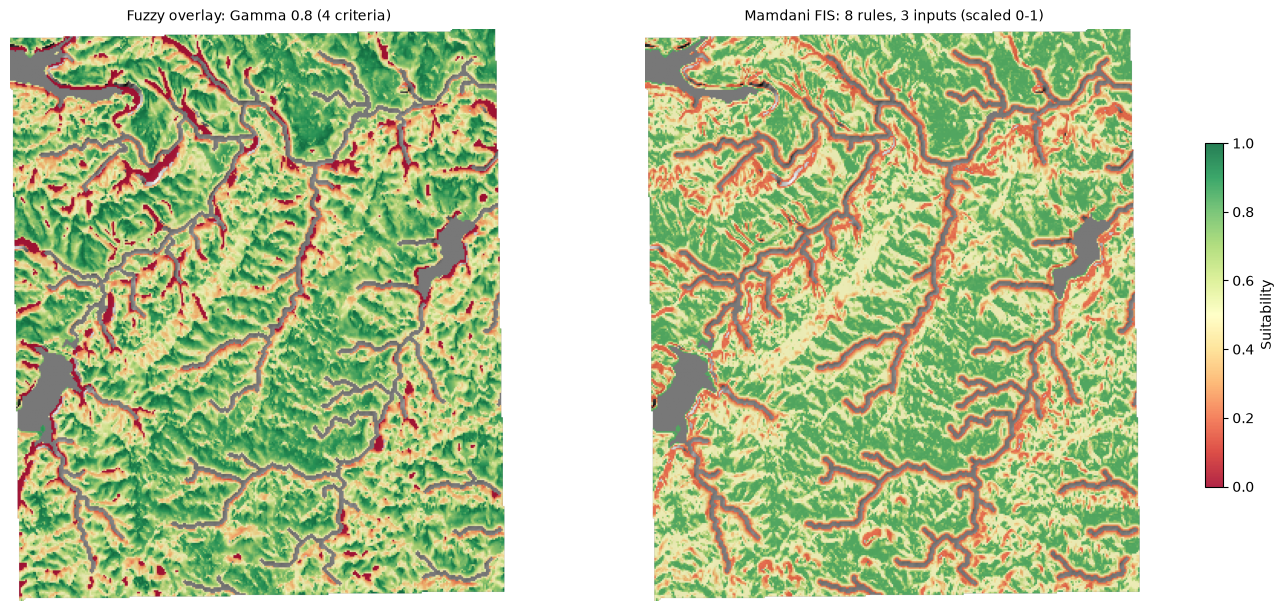

FIS vs Gamma 0.8: Jaccard (top 20%) = 0.476 | Spearman rho = 0.803


In [12]:
# Side-by-side maps: fuzzy gamma overlay vs Mamdani FIS (scaled to 0-1).
fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout="constrained")  # two-method comparison
im = show(baseline, "Fuzzy overlay: Gamma 0.8 (4 criteria)", axes[0])  # overlay map
show(fis / 100, "Mamdani FIS: 8 rules, 3 inputs (scaled 0-1)", axes[1])  # FIS map on [0, 1]
fig.colorbar(im, ax=axes, shrink=0.6, label="Suitability")  # shared colourbar
plt.show()  # render the figure

j, rho = compare(fis, baseline)  # note: compare uses top_quantile on raw values; FIS scale differs but ranks matter
print(f"FIS vs Gamma 0.8: Jaccard (top 20%) = {j:.3f} | Spearman rho = {rho:.3f}")  # agreement summary



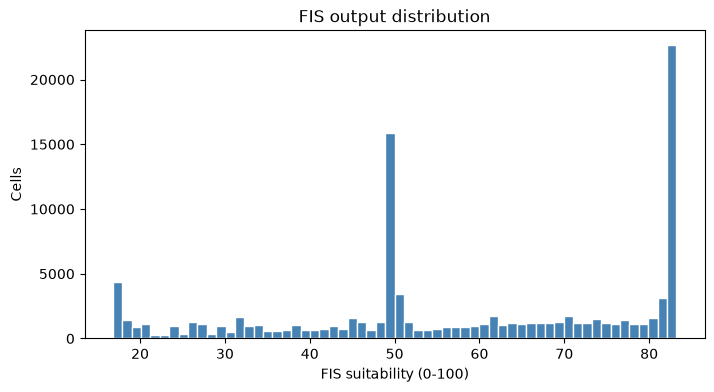

In [13]:
# Histogram of FIS suitability scores on feasible cells (0-100 scale).
fig, ax = plt.subplots(figsize=(8, 4))  # FIS output distribution
ax.hist(fis_vals, bins=60, color="steelblue", edgecolor="white")  # score histogram
ax.set(xlabel="FIS suitability (0-100)", ylabel="Cells", title="FIS output distribution")  # labels
plt.show()  # render the figure



The FIS output is **clustered** around the centroids of the output terms (low, medium, high). This is typical of Mamdani systems with few rules: the result behaves like an ordinal classification with smooth transitions, while Gamma overlay gives a more continuous surface.

The two maps agree on the **broad pattern** (ρ ≈ 0.8), but only about half of their top-20% areas coincide. There are three reasons:

- The FIS uses **three inputs** and ignores topographic position.
- Its output is **clustered**, so many cells share the same "high" value and the top-20% cutoff falls among tied values.
- Its rules encode different logic. Gentle **north-facing** slopes are *medium* under the rules, while the overlay penalizes them more smoothly through the exposure criterion.

Disagreement between two reasonable models is useful information. It shows where the result depends on modeling choices rather than on the data.

## Choosing a method

| Method | Logic | Weights | Strengths | Limitations |
|---|---|---|---|---|
| Boolean (Module 3) | Crisp AND | None | Simple, transparent | Hard edges, no ranking |
| WLC (Module 4) | Fully compensatory | Explicit | Intuitive, easy to weight | Strengths mask weaknesses |
| Fuzzy overlay (Modules 6-7) | Graded, adjustable from strict to lenient | Optional (4) | Removes hard edges, few parameters | One operator for all interactions |
| Weighted fuzzy (4) | Graded + importance | Explicit | Combines both ideas | More parameters to justify |
| Fuzzy inference (5) | Expert IF-THEN rules | Implicit in rules | Interpretable, captures interactions | Rule base grows quickly with inputs |

**Practical recommendation:** start with constraints plus **fuzzy Gamma or AND overlay**. Add weights when stakeholders clearly disagree about importance, and move to a **FIS** when experts describe suitability as *conditional rules* rather than independent criteria.

## Exercises

1. Add **TPI** to the FIS with terms *valley*, *mid-slope*, and *ridge*, and add two rules that use it. How many rules would a complete rule base with four inputs need?
2. Replace centroid defuzzification with **mean of maximum** (`skf.defuzz(..., "mom")`) on the validation cells. How do the results differ?
3. Repeat the OAT analysis in 8.3 with the **AND** operator. Which operator is more sensitive to the parameters?
4. Search for weights that maximize the Jaccard agreement between weighted Gamma and the FIS. What do those weights reveal about the implicit priorities in the rule base?

## Key takeaways

- Report fuzzy results with their **γ and parameters**, and prefer **relative thresholds** (top *k*%) over absolute ones.
- **OAT sensitivity** with Jaccard agreement shows which expert parameters drive the result.
- Weighted fuzzy operators add explicit **importance** while keeping the fuzzy logic.
- A **Mamdani FIS** turns expert rules into a suitability map, can be vectorized for rasters, and should be validated against a reference implementation.

---

## Part II summary

| Module | Topic | Main techniques |
|---|---|---|
| 5 | Fuzzy foundations | Membership functions, hedges, overlay operators, ``geolattice.spatial_analysis.multi_criteria_suitability_analysis`` |
| 6 | Fuzzy polygons | NY clinic siting, limiting-criterion map, comparison with Boolean and WLC |
| 7 | Fuzzy rasters | DEM criteria, circular aspect, conditional membership, constraints, site extraction |
| 8 | Advanced | γ and parameter sensitivity, weighted fuzzy, Mamdani FIS |

**Part III: Weighting and Uncertainty** covers AHP, entropy weights, Monte Carlo and Sobol sensitivity analysis, and optimization-based site selection.

